# BPL Plotting and Pictures

In [1]:
!pip install -U basedpl

In [2]:
%load_ext basedpl.notebooks

In [3]:
import basedpl
basedpl.__version__

'0.1.91'

## Seeing your data

Numbers are easier to understand as pictures. BPL can draw **charts** (`•plot`), **images** made from numbers (`•image`), and **drawings** made of shapes (`•svg`), right in the notebook. This dialog builds up a chart one setting at a time, then makes an image from numbers and a small drawing from data.

BPL docs: [Plots](https://answerdotai.github.io/basedpl/plot.html) · [`•image`](https://answerdotai.github.io/basedpl/system/image.html) · [XML and SVG](https://answerdotai.github.io/basedpl/xml.html)

Glyphs and ideas this dialog teaches:

| Glyph | Plain English |
|---|---|
| `•plot data` | draw a chart (a line chart by default) |
| `opts •plot data` | a chart with settings, such as `["mark":"bar" "title":"…"]` |
| `"mark"` | the kind of chart: `"line"`, `"point"`, `"bar"` or `"cell"` (a coloured grid) |
| `p.y.title←"…"` | change one setting of a chart that's stored in `p` |
| `p.series.name.mark←…` | change one series of the chart |
| `•image numbers` | show numbers from 0 to 1 as a picture: grey, or red-green-blue |
| `•element "circle"` | make a function that builds an SVG shape |
| `•svg shapes` | put shapes together into a drawing |
| `["fps":10] •image frames` | play an animation: frames × rows × columns, at 10 frames a second |
| `(t k k)⌷x` | pick frames `t`, rows `k` and columns `k` of `x` |
| `c.y.scale←"log"` | a log scale on the y axis: each grid line is 10 times the one below |
| `a{…}⊗b` | outer product with a function: call it on every pair from `a` and `b` |

Other glyphs used along the way:

| Glyph | Plain English |
|---|---|
| `←` | store a value in a name |
| `⍝` | comment: BPL ignores the rest of the line |
| `["key":value]` | a record: settings or columns with names |
| `keys:values` | put names on the items of a list |
| `ι` `ρ` `÷` | positions, reshape, divide |
| `×⊗` | outer product: multiply every item by every item, giving a table |
| `↦10` | the numbers 1 to 10 |
| `⊃` | mix a list of tables into one bigger array |
| `2 0 1⍉` | reorder axes: here, move the first axis to the end |
| `⌹` `+.×` | best-fit line, matrix product |
| `¨` | each |
| `v.[i]` | item `i` of `v` |
| `⌺` | stencil: work on each cell with its neighbours |
| `= ∧ ∨ ≥ <` | compare, and, or (answers `$t` or `$f`) |
| `⌊` | round down |
| `⊛` | natural logarithm |
| `∂` | slope (derivative), from 14 Autodiff and ML |

### The data

A week of temperatures (°C) and rainfall (mm), Monday to Sunday.

In [4]:
%%bpl
days←"Mon" "Tue" "Wed" "Thu" "Fri" "Sat" "Sun"
temps←12 15 11 18 20 14 9
rain←0 2 5 0 0 1 8

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

### Charts

#### 1. A first chart

- `•plot temps` draws a line chart of the list, with the positions 0 to 6 along the bottom.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

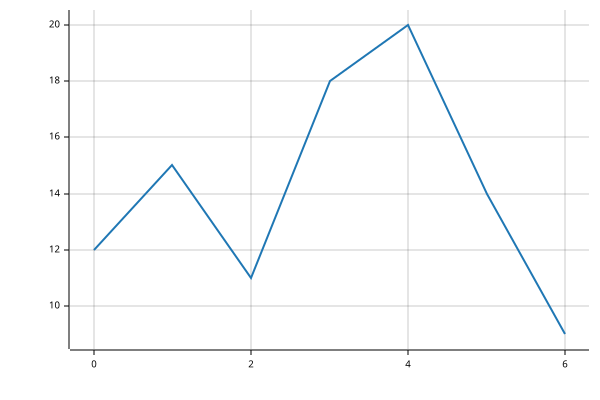

In [5]:
%%bpl
•plot temps

#### 2. Labels along the bottom

- `days:temps` puts a day name on each temperature (a keyed list). `•plot` uses the names as the labels along the bottom.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

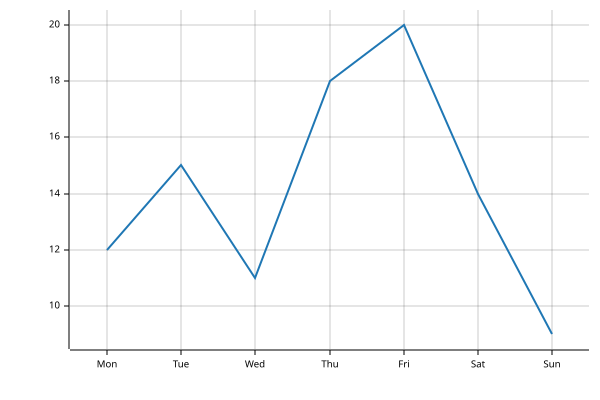

In [6]:
%%bpl
•plot days:temps

#### 3. A bar chart with a title

- Settings go in a record on the **left**. `"mark":"bar"` makes a bar chart, and `"title"` adds a title.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

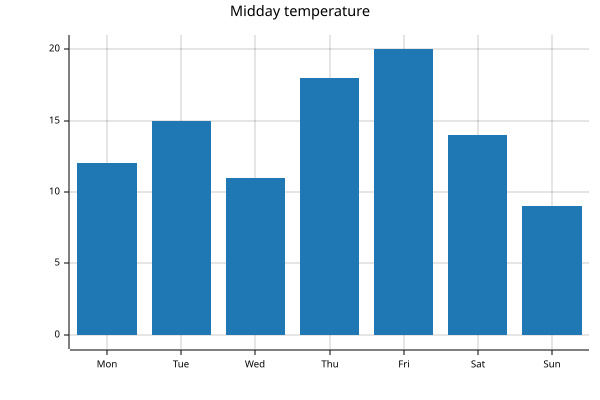

In [7]:
%%bpl
["mark":"bar" "title":"Midday temperature"] •plot days:temps

#### 4. Change a setting afterwards

- `•plot` gives back a chart that you can store in a name and change, like any record.
- `q.y.title←"°C"` adds a title to the y axis (the side). Showing `q` again draws the changed chart.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

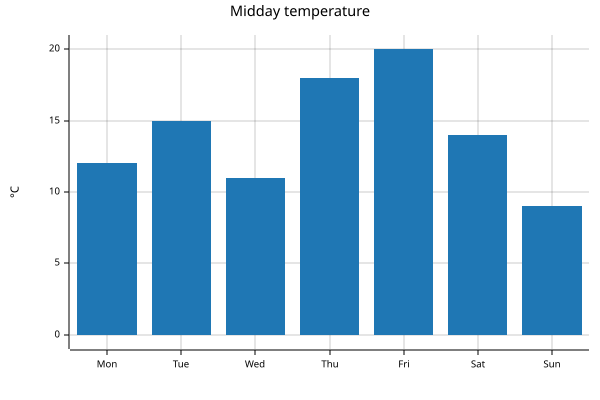

In [8]:
%%bpl
q←["mark":"bar" "title":"Midday temperature"] •plot days:temps
q.y.title←"°C"       ⍝ name the y axis
q

#### 5. Two series on one chart

- A table (a record of columns) plots each column as its own line, with a legend for their names.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

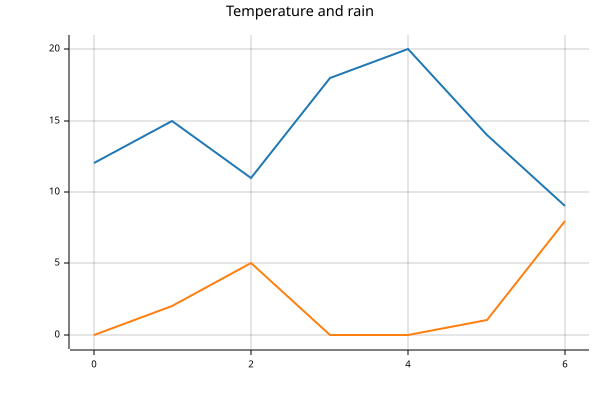

In [9]:
%%bpl
["title":"Temperature and rain"] •plot ["temp":temps "rain":rain]

#### 6. Points and a best-fit line

- A column called `"x"` gives the x positions. Here: noisy points near the line `1+2×x`, and the best-fit line through them (`⌹`, from linear algebra).
- `"mark":"point"` draws dots. Then `s.series.fit.mark←"line"` draws just the `fit` column as a line.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

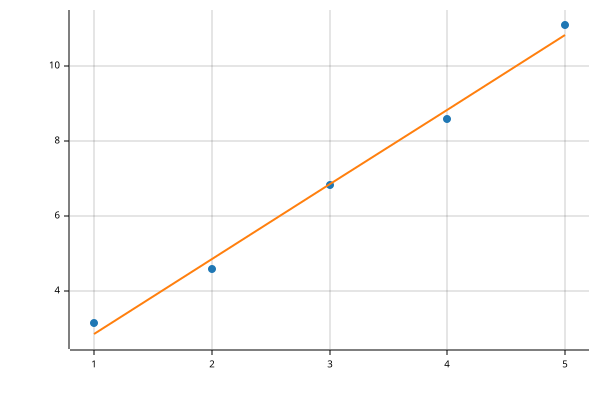

In [10]:
%%bpl
x←1 2 3 4 5
•prefs ["seed":3]
yn←(1+2×x)+¯0.5+¿5ρ0        ⍝ points near a line
ones←5ρ1
X←⍉⊃[ones x]
fit←X+.×yn⌹X                ⍝ the best-fit line at each x
s←["mark":"point"] •plot ["x":x "data":yn "fit":fit]
s.series.fit.mark←"line"    ⍝ draw the fit as a line
s

#### 7. A coloured grid

- `"mark":"cell"` draws a table as a grid of coloured squares: a *heatmap*. Bigger numbers get brighter colours, and `"colorbar"` shows the scale.
- Here: a multiplication table. `n×⊗n` (outer product) multiplies every item of `n` by every item of `n`, giving a 10×10 table.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

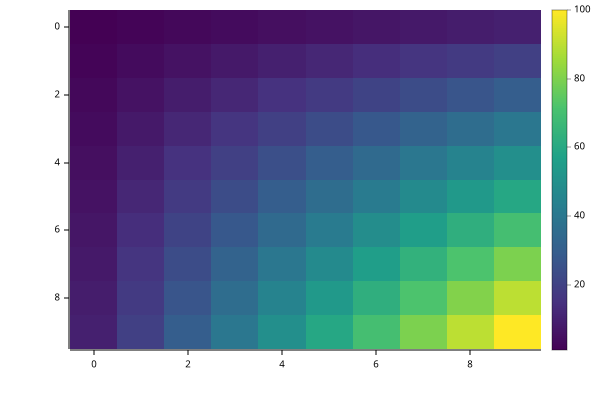

In [11]:
%%bpl
n←↦10                               ⍝ 1 to 10
times←n×⊗n                          ⍝ a 10×10 multiplication table
["mark":"cell" "colorbar":$t] •plot times

### Pictures

#### 8. An image from numbers

- `•image` shows a table of numbers from 0 to 1 as a picture: 0 is black and 1 is white.
- `100 100ρ(ι100)÷99` repeats 0 to 1 along every row, giving a fade from black on the left to white on the right.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

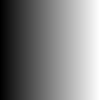

In [12]:
%%bpl
•image 100 100ρ(ι100)÷99      ⍝ a grey fade

#### 9. A colour image

- A colour picture has **three** numbers per pixel: red, green and blue. Its shape is rows × columns × 3.
- `ramp` goes from 0 to 1 in 100 steps. With `×⊗` (step 7), `ramp×⊗ones` makes a table whose rows get brighter going down: that's red. `ones×⊗ramp` gets brighter going right: green. Blue is a steady 0.5.
- `⊃[r g b]` stacks them into a 3×100×100 array. `2 0 1⍉` moves the colour axis to the end, giving 100×100×3.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

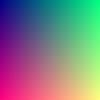

In [13]:
%%bpl
ramp←(ι100)÷99           ⍝ 0 to 1 in 100 steps
ones←100ρ1
r←ramp×⊗ones             ⍝ red: brighter going down
g←ones×⊗ramp             ⍝ green: brighter going right
b←100 100ρ0.5            ⍝ blue: steady
•image 2 0 1⍉⊃[r g b]    ⍝ rows × columns × colours

### Drawings

#### 10. Shapes with SVG

- SVG is the web's format for drawings made of shapes. `•element "circle"` gives a function, `circle`, that builds a circle. Its settings (`cx`, `cy` for the centre, `r` for the radius, `fill` for the colour) go in a record on the left.
- `•svg` puts shapes into a drawing. The drawing area runs from 0 to 100 across and down.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

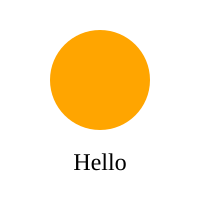

In [14]:
%%bpl
[text circle]←•element "text" "circle"
dot←["cx":50 "cy":40 "r":25 "fill":"orange"] circle ""
lab←["x":50 "y":85 "text-anchor":"middle"] text "Hello"
["width":200 "height":200] •svg dot lab

#### 11. A drawing from data

- Make one dot per day with `¨`. Day `ω` goes `10+13×ω` across, and its temperature sets how far up it is. (In SVG, y counts **down** from the top, so a hotter day needs a smaller y.)
- This is the start of building your own kind of chart.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

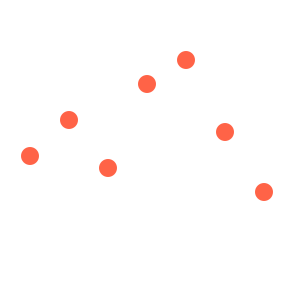

In [15]:
%%bpl
spot←{cx←10+13×ω ◇ cy←100-4×temps.[ω] ◇ ["cx":cx "cy":cy "r":3 "fill":"tomato"] circle ""}
dots←spot¨ι7                   ⍝ one dot per day
["width":300 "height":300] •svg dots

### Animations

#### 12. An animation is a stack of pictures

- An animation is just several pictures, one after another. In BPL that's an array whose **first** axis is the frames: frames × rows × columns.
- `((ι20)÷19)×⊗50 50ρ1` uses `×⊗` (step 7) to make 20 frames of 50×50, each a little brighter than the last.
- `["fps":10] •image` plays the frames at 10 frames per second, and loops.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

[20 50 50]ₓ

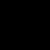

In [16]:
%%bpl
fade←((ι20)÷19)×⊗50 50ρ1    ⍝ 20 frames, black to white
ρfade                       ⍝ frames, rows, columns
["fps":10] •image fade      ⍝ 10 frames a second

#### 13. Something that moves

- Write a function that draws **one** frame, then make one frame per position.
- `frame ω` is a 30×100 picture with a white bar 10 pixels wide, starting at column `ω`.
- `frame¨ι91` makes 91 frames, one for each starting column. `⊃` (mix, from 02 Shapes and Nesting) stacks them into one 91×30×100 array.

In [17]:
%%bpl
x←ι100                                   ⍝ column numbers
frame←{30 100ρ(x≥ω)∧x<ω+10}             ⍝ a bar starting at column ω
frames←⊃frame¨ι91                        ⍝ 91 frames
["fps":30] •image frames                 ⍝ the bar slides across

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

#### 14. The Game of Life, animated

- `lifew` is one step of Conway's Game of Life on a wrap-around grid. Stencil (`⌺`) counts each cell's live neighbours, then a live cell survives with 2 or 3, and a dead cell comes alive with exactly 3.
- Start with a *glider* in the corner of a 20×20 grid. `g.[row;columns]←1` switches cells on.
- `lifew⍣(ι80)` keeps 80 generations, and `⊃` stacks them into frames.
- Each cell is only one pixel, so make it bigger. `k` repeats each row and column number 8 times (0 0 0 0 0 0 0 0 1 1 …), and `(t k k)⌷gens` picks every frame `t`, with rows `k` and columns `k`.
- On a 20×20 wrap-around grid, the glider is back where it started after 80 steps, so the animation loops smoothly.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

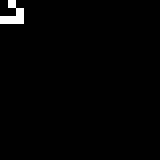

In [18]:
%%bpl
s←3 3
wrap←["size":s "edge":"wrap"]
lifew←{n←({+/,ω}⌺wrap⁝ω)-ω ◇ (n=3)∨ω∧n=2}   ⍝ one step of Life
g←20 20ρ0
g.[0;1]←1 ◇ g.[1;2]←1 ◇ g.[2;0 1 2]←1      ⍝ a glider
gens←⊃lifew⍣(ι80)⁝g                        ⍝ 80 generations as frames
t←ι80
k←⌊(ι160)÷8                                ⍝ each row/column 8 times
big←(t k k)⌷gens                           ⍝ 80 × 160 × 160
["fps":12] •image big

### Machine learning, visualised

These charts show what happens inside the training from 14 Autodiff and ML. The first cell sets up the same small problem: five points on the line `1+2×x`, a `loss` that measures how wrong a line `a b` is, and a `train` step of gradient descent. `h` keeps the line after each of the first 100 training steps.

#### 15. The loss falling

- `loss¨h` is the loss after each step. A line chart of it is the classic *training curve*.
- The loss falls from 57 to almost 0, so most of the chart would be squashed against the bottom. `c.y.scale←"log"` uses a log scale on the y axis, where each grid line is 10 times the one below, so you can see the whole fall.

In [19]:
%%bpl
sq←×⍨
x←1 2 3 4 5
y←3 5 7 9 11
line←{[a b]←α ◇ a+b×ω}                              ⍝ a + b×x
loss←{pred←ω line x ◇ err←y-pred ◇ (+/sq err)÷≢x}  ⍝ mean squared error
train←{ω-0.05×loss∂ω}                               ⍝ one step of gradient descent
h←train⍣(ι100)⁝0 0                                  ⍝ the line after each step

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

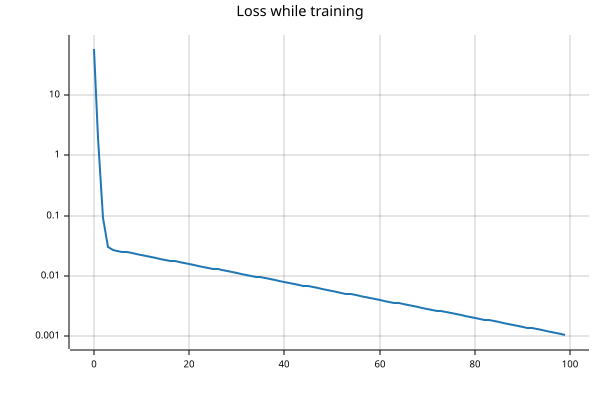

In [20]:
%%bpl
c←["title":"Loss while training"] •plot loss¨h
c.y.scale←"log"          ⍝ log scale: see the whole fall
c

#### 16. The line getting better

- Draw the line the model has at the start, and after 2, 5 and 99 steps, together with the data points.
- `(ω⊃h) line x` is the line after step `ω`. `¨` does it for each of 0, 2, 5 and 99.
- Each value is picked into the record with `⊃`, which has no spaces, so it stays one item inside the brackets.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

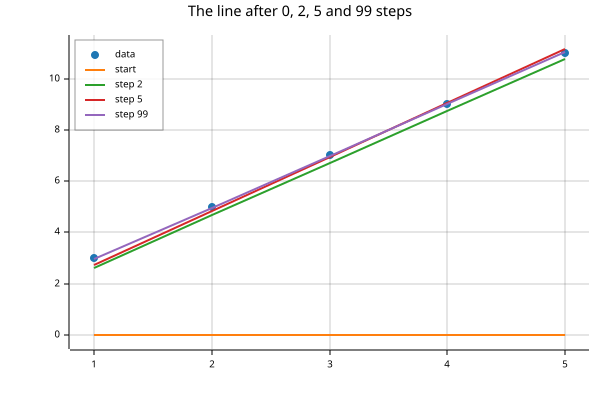

In [21]:
%%bpl
fits←{(ω⊃h) line x}¨0 2 5 99      ⍝ the line at 4 moments
fp←["title":"The line after 0, 2, 5 and 99 steps"] •plot ["x":x "data":y "start":0⊃fits "step 2":1⊃fits "step 5":2⊃fits "step 99":3⊃fits]
fp.series.data.mark←"point"       ⍝ the data as dots
fp.legend.position←"top-left"
fp

#### 17. Learning rate: smooth or jumpy

- Back to the valley `f`, lowest at 5. Track the position after each step for two learning rates.
- With 0.1, each step moves a little closer to 5: a smooth curve.
- With 0.9, each step **overshoots** to the other side of 5, so the position zigzags, though it still settles. (Above 1, it would zigzag further away each time.)

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

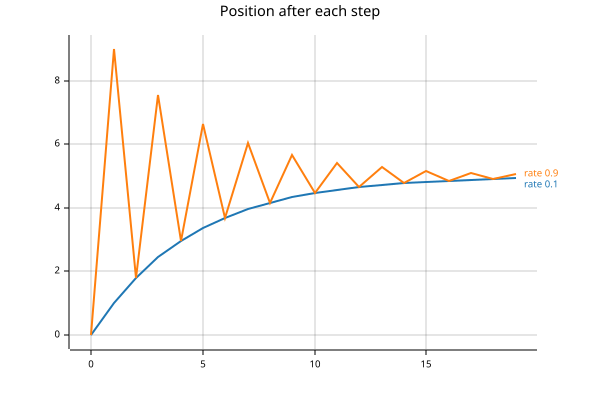

In [22]:
%%bpl
f←{sq ω-5}                        ⍝ a valley, lowest at 5
slow←{ω-0.1×f∂ω}
jumpy←{ω-0.9×f∂ω}
["title":"Position after each step" "legend":"end"] •plot ["rate 0.1":slow⍣(ι20)⁝0 "rate 0.9":jumpy⍣(ι20)⁝0]

#### 18. The loss landscape

- The loss depends on two numbers, `a` and `b`. Work it out for every pair on a grid, and draw it as a heatmap: dark is a low loss, bright is a high one.
- `as{loss α ω}⊗bs` is an outer product with a function: it calls `loss` on every pair of an `a` from `as` and a `b` from `bs`.
- `⊛1+L` (the log of 1 + loss) squeezes the big values so the shape shows up.
- Rows are `a` and columns are `b`, both from 0 to 4 in steps of 0.1. The low loss forms a long dark **valley**: raising `a` while lowering `b` a little gives a line that is nearly as good. The very lowest point is at row 10, column 20, which is `a=1`, `b=2`: the line gradient descent found. Gradient descent walks down into the valley, then along it to that point.

Javascript(if (window.loadBplInput) window.loadBplInput();
else import('https://cdn.jsdelivr.net/npm/basedpl/browser/bpl-editor.js').then(m => m.install());)

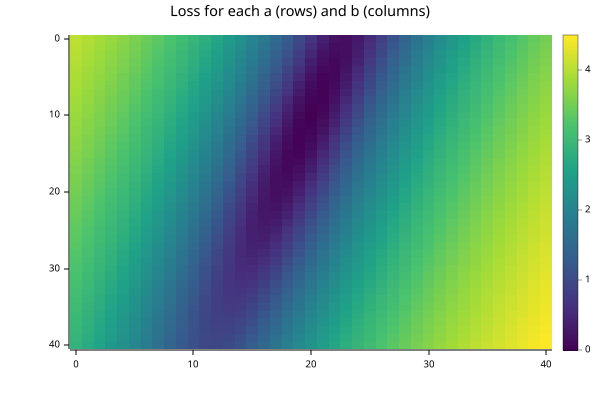

In [23]:
%%bpl
as←(ι41)÷10                       ⍝ a from 0 to 4
bs←(ι41)÷10                       ⍝ b from 0 to 4
L←as{loss α ω}⊗bs                 ⍝ loss for every pair
["mark":"cell" "colorbar":$t "title":"Loss for each a (rows) and b (columns)"] •plot ⊛1+L

### Your turn

1. Draw the rainfall as a bar chart with the day names along the bottom.
   *Hint:* copy step 3 with `days:rain`.
2. Give your chart from exercise 1 a y-axis title of `"mm"`.
3. Plot the 3-day moving average of the temperatures.
   *Hint:* `(+/3↕temps)÷3`.
4. Make a grey image that fades from black at the top to white at the bottom.
   *Hint:* `⍉` turns step 8's left-to-right fade into a top-to-bottom one.
5. Change the dots in step 11 to blue, and make them bigger.
6. Make the fade in step 12 go from white to black instead.
   *Hint:* `1-fade`.
7. Slow the glider in step 14 down to 4 frames a second.
8. Add a third learning rate, 1.05, to step 17's chart. What happens to its position?
   *Hint:* another entry, such as `"rate 1.05":wild⍣(ι20)⁝0`, with `wild←{ω-1.05×f∂ω}`.